# C2 · Rule base thresholds (live session)

Draft playbook rules on the real fact vocabulary (`anchorai.reasoning.facts.KNOWN_FACTS`). We run them on all members,
look at how often each rule fires and how the patterns line up with churn **on the training split**, then pick the
thresholds. The agreed thresholds are edited straight into `anchorai/reasoning/rules/*.yaml`.

Thresholds are **not** tuned against the scenario's `true_uplift`: that ground truth is what E4 and E6 are scored on.

Needs `uv run anchorai data build` (and `uv run anchorai kg load` for the KG rules).

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anchorai.discovery.scores import load_features, load_scores
from anchorai.knowledge.signals import load_kg_facts
from anchorai.reasoning.engine import load_rule_files, run
from anchorai.reasoning.facts import KNOWN_FACTS, build_facts
from anchorai.reasoning.validate import validate
from anchorai.scenario.offers import OFFER_CATALOG
from anchorai.scenario.tables import read_tables
from anchorai.schemas import Channel

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

tables = read_tables()
members = tables["members"].set_index("member_id")
scores = load_scores().set_index("member_id")
features = load_features()
kg = load_kg_facts()
facts = build_facts(scores, features, tables["interventions"], kg)
train = members["split"] == "train"
print(f"{len(facts)} members | KG facts: {'yes' if kg is not None else 'no (run kg load)'} | train churn rate {members.loc[train, 'churn'].mean():.1%}")

4000 members | KG facts: yes | train churn rate 26.5%


## 1. What the thresholds sit on

Churn rate by bin, training split only. A good threshold sits where the churn rate changes, not just where the data is dense.

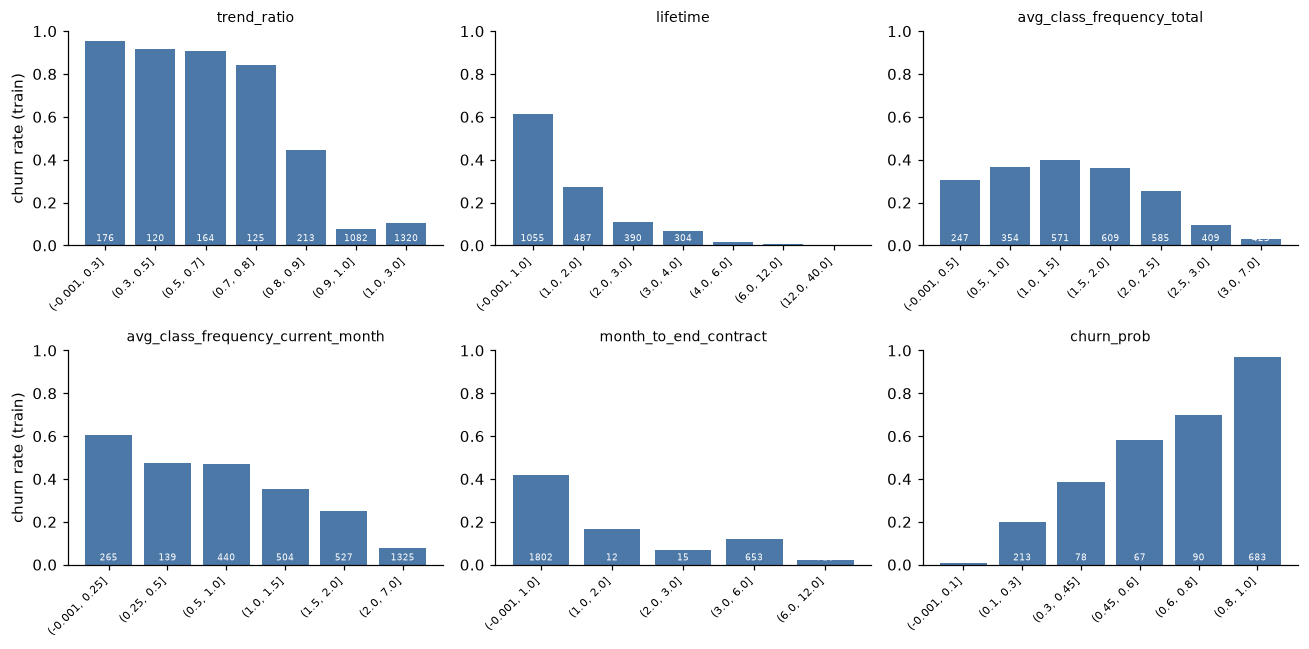

In [2]:
def churn_by_bin(col, bins):
    x = features.loc[train, col] if col in features else scores.loc[train, col]
    b = pd.cut(x, bins, include_lowest=True)
    return members.loc[train].groupby(b, observed=True)["churn"].agg(["size", "mean"]).rename(columns={"mean": "churn_rate"})

THRESHOLD_COLUMNS = {
    "trend_ratio": [0, 0.3, 0.5, 0.7, 0.8, 0.9, 1.0, 3],
    "lifetime": [0, 1, 2, 3, 4, 6, 12, 40],
    "avg_class_frequency_total": [0, 0.5, 1, 1.5, 2, 2.5, 3, 7],
    "avg_class_frequency_current_month": [0, 0.25, 0.5, 1, 1.5, 2, 7],
    "month_to_end_contract": [0, 1, 2, 3, 6, 12],
    "churn_prob": [0, 0.1, 0.3, 0.45, 0.6, 0.8, 1],
}
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, (col, bins) in zip(axes.flat, THRESHOLD_COLUMNS.items()):
    t = churn_by_bin(col, bins)
    ax.bar(range(len(t)), t["churn_rate"], color="#4c78a8")
    ax.set_xticks(range(len(t)), [str(i) for i in t.index], rotation=45, ha="right", fontsize=7)
    ax.set_title(col, fontsize=9); ax.set_ylim(0, 1)
    for i, n in enumerate(t["size"]):
        ax.text(i, 0.02, n, ha="center", fontsize=6, color="white")
axes[0, 0].set_ylabel("churn rate (train)"); axes[1, 0].set_ylabel("churn rate (train)")
fig.tight_layout(); fig.savefig(FIG / "c2_threshold_bins.png"); plt.show()

## 2. The rule base

The rules live in `anchorai/reasoning/rules/` (`derive.yaml`, `playbook.yaml`, `guardrails.yaml`). Edit thresholds
there and re-run from this cell. The validator flags unknown facts, contradictions and unreachable rules.

In [3]:
rules = load_rule_files()
offers = [o["offer_id"] for o in OFFER_CATALOG]
issues = validate(rules, KNOWN_FACTS, offers, [c.value for c in Channel])
print(len(rules), "rules;", len(issues), "issues")
pd.DataFrame([i.model_dump() for i in issues])

29 rules; 0 issues


""


## 3. Run on every member

In [4]:
start = time.perf_counter()
outcomes = {m: run(rules, f, m) for m, f in facts.items()}
print(f"{len(outcomes)} members in {time.perf_counter() - start:.2f}s")

firings = pd.Series([f.rule_id for o in outcomes.values() for f in o.firings]).value_counts()
summary = pd.DataFrame({"fired": firings, "share": firings / len(outcomes)})
summary["kind"] = summary.index.map({r.id: r.kind for r in rules})
summary.reindex([r.id for r in rules]).fillna(0).round(3)

4000 members in 0.57s


,fired,share,kind
D01_falling_regular,72.0,0.018,derive
D02_new_member,1330.0,0.332,derive
D03_disengaged,315.0,0.079,derive
D04_new_and_absent,258.0,0.064,derive
D05_high_value_at_risk,957.0,0.239,derive
D06_social_member,1234.0,0.308,derive
D07_lost_instructor,186.0,0.046,derive
D08_class_cancelled,170.0,0.042,derive
G01_contact_fatigue,475.0,0.119,guardrail
G02_offer_cap,0.0,0.000,0


In [5]:
allowed = pd.Series({m: len(o.allowed) for m, o in outcomes.items()})
blocked_all = pd.Series({m: "all" in o.blocked for m, o in outcomes.items()})
first_offer = pd.Series({m: o.allowed[0].offer_id if o.allowed else "none" for m, o in outcomes.items()})
band = scores["risk_band"]
print(f"blocked entirely: {blocked_all.mean():.1%} | no allowed action: {(allowed == 0).mean():.1%}")
pd.crosstab(band, first_offer, margins=True)

blocked entirely: 11.9% | no allowed action: 69.3%


col_0,checkin_message,class_pass,discount_1m,free_pt_session,none,All
risk_band,,,,,,
high,70,5,24,731,140,970
low,243,0,0,0,2618,2861
medium,121,29,0,4,15,169
All,434,34,24,735,2773,4000


## 4. Do the derived patterns mean something? (training split, real churn label)

Each pattern should pick out members whose churn rate differs from the base rate. A pattern with base-rate churn is noise.

**Caveat:** `trend_ratio`, `avg_class_frequency_current_month` and `month_to_end_contract` are in
`features.SUSPECT` (possibly measured in the churn month; see `results/a_leakage.md`). Lift for patterns built on them
is optimistic; say so wherever these numbers are quoted.

In [6]:
patterns = [r.then.assert_ for r in rules if r.kind == "derive"]
names = sorted({k for p in patterns for k in p})
rows = []
for name in names:
    has = pd.Series({m: bool(o.facts.get(name)) for m, o in outcomes.items()})
    t = has & train
    rows.append({"pattern": name, "members": int(has.sum()), "train_churn": members.loc[t[t].index, "churn"].mean()})
base = members.loc[train, "churn"].mean()
patterns_table = pd.DataFrame(rows).set_index("pattern").assign(lift=lambda d: d["train_churn"] / base)
patterns_table.round(3)

,members,train_churn,lift
pattern,,,
disengaged,365,0.774,2.918
falling_regular,72,1.000,3.769
high_value_at_risk,957,0.940,3.542
new_member,1330,0.612,2.308
routine_disrupted,356,0.179,0.676
social_member,1234,0.164,0.620


## 5. Decide

For each threshold, note the value you pick and why (it goes into the rule's `description`, and `source` stays honest):

- falling regular: `avg_class_frequency_total >=` ?, `trend_ratio <=` ?
- new member: `lifetime <=` ? months
- disengaged: `avg_class_frequency_current_month <` ?
- contract ending: `month_to_end_contract <=` ?
- low-risk paid-offer block: keep or drop?

Then save the table below; it is the starting point for E6.

In [7]:
summary.to_csv(RES / "c2_rule_firings.csv")
patterns_table.to_csv(RES / "c2_pattern_churn.csv")

## 6. Check against the simulated interviews (2026-10-16)

Three AI-simulated persona interviews (`Miscellaneous/interviews/*_simulated.md`; no real person was interviewed) said:
a 20% dip is noise and a drop of about half is the signal (D01); new members should be judged on how often they come,
not on the trend; a member who always came rarely is not disengaged (D03). The cells below test each view on the
training split with the real churn label.

**Decided 2026-10-16:**
- D01 `trend_ratio <= 0.7`, a compromise: the data shows smaller drops also churn, the interviews call them noise.
- D03 also requires `trend_ratio < 0.8`, so members who always came rarely are not flagged.
- P01 keeps the trend: it separates churners better than visits this month, even for new members.


In [8]:
from sklearn.metrics import roc_auc_score

tr = features.loc[train].assign(churn=members.loc[train, "churn"])
tr["tenure"] = pd.cut(tr["lifetime"], [-1, 1, 5, 100], labels=["new (0-1)", "mid (2-5)", "long (6+)"])

# Which signal separates churners better within each tenure group: the trend or visits this month?
signal = pd.DataFrame({
    t: {"members": len(g), "churn_rate": g["churn"].mean(),
        "auc_trend": roc_auc_score(g["churn"], -g["trend_ratio"]),
        "auc_visits_this_month": roc_auc_score(g["churn"], -g["avg_class_frequency_current_month"])}
    for t, g in tr.groupby("tenure", observed=True)
}).T.round(3)
signal.to_csv(RES / "c2_interview_signal_by_tenure.csv")
signal

,members,churn_rate,auc_trend,auc_visits_this_month
new (0-1),1055.0,0.612,0.807,0.755
mid (2-5),1407.0,0.141,0.857,0.803
long (6+),738.0,0.007,0.990,0.787


In [9]:
regular = tr["avg_class_frequency_total"] >= 2
d01 = pd.DataFrame([
    {"trend_ratio_max": th, "members": int((regular & (tr["trend_ratio"] <= th)).sum()),
     "churn_rate": tr.loc[regular & (tr["trend_ratio"] <= th), "churn"].mean()}
    for th in (0.5, 0.6, 0.7, 0.8, 0.9)
]).round(3)

low_now = tr["avg_class_frequency_current_month"] < 0.5
d03 = pd.DataFrame([
    {"rule": name, "members": int(s.sum()), "churn_rate": tr.loc[s, "churn"].mean(),
     "long_timers": int((s & (tr["lifetime"] >= 6)).sum()), "long_timer_churn": tr.loc[s & (tr["lifetime"] >= 6), "churn"].mean()}
    for name, s in [("visits < 0.5 (old D03)", low_now), ("and fell: trend < 0.8 (new D03)", low_now & (tr["trend_ratio"] < 0.8)),
                    ("always low (excluded)", low_now & (tr["trend_ratio"] >= 0.8))]
]).round(3)
d01.to_csv(RES / "c2_interview_d01.csv", index=False)
d03.to_csv(RES / "c2_interview_d03.csv", index=False)
display(d01)
d03

,trend_ratio_max,members,churn_rate
0,0.5,22,1.000
1,0.6,38,1.000
2,0.7,61,1.000
3,0.8,102,1.000
4,0.9,142,0.965


,rule,members,churn_rate,long_timers,long_timer_churn
0,visits < 0.5 (old D03),404,0.562,61,0.033
1,and fell: trend < 0.8 (new D03),249,0.831,15,0.133
2,always low (excluded),155,0.129,46,0.000


**Look for:** `auc_trend` above `auc_visits_this_month` in every tenure group (trend wins); D01 churn rate staying high
as the threshold rises (smaller drops still churn); the excluded "always low" row with a low churn rate (those were D03's
false alarms). Caveat: the Kaggle current-month frequency partly reflects members already leaving, which flatters the trend.
